![Imgur](https://i.imgur.com/5pXzCIu.png)

# Data Science va Sun'iy Intellekt Praktikum

## 5-MODUL. Machine Learning

### Portfolio uchun vazifa: Toshkent shahrida uylarning narxini aniqlash.

Ushbu amaliyotda sizning vazifangiz berilgan ma`lumotlar asosida Toshkent shahridagi uylarning narxini aniqlash.

In [131]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('https://raw.githubusercontent.com/anvarnarz/praktikum_datasets/main/housing_data_08-02-2021.csv')
df.head()

,location,district,rooms,size,level,max_levels,price
0,"город Ташкент, Юнусабадский район, Юнусабад 8-...",Юнусабадский,3,57,4,4,52000
1,"город Ташкент, Яккасарайский район, 1-й тупик ...",Яккасарайский,2,52,4,5,56000
2,"город Ташкент, Чиланзарский район, Чиланзар 2-...",Чиланзарский,2,42,4,4,37000
3,"город Ташкент, Чиланзарский район, Чиланзар 9-...",Чиланзарский,3,65,1,4,49500
4,"город Ташкент, Чиланзарский район, площадь Актепа",Чиланзарский,3,70,3,5,55000


In [132]:
df.shape

(7565, 7)

In [133]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   location    7565 non-null   object
 1   district    7565 non-null   object
 2   rooms       7565 non-null   int64 
 3   size        7565 non-null   object
 4   level       7565 non-null   int64 
 5   max_levels  7565 non-null   int64 
 6   price       7565 non-null   object
dtypes: int64(3), object(4)
memory usage: 413.8+ KB


# Malumotlarni o'qiymiz
# Bizda quyidagi 7 ta ustun va 7565 ta qator mavjud
- `location` - sotilayotgan uy manzili
- `district` - uy joylashgan tuman
- `rooms` - xonalar soni
- `size` - uy maydoni (kv.m)
- `level` - uy joylashgan qavat
- `max_levels` - ja'mi qavatlar soni
- `price` - uy narxi

##  Biz bu loyihamnizni CRSIP-DM Metolodgiyasi yordamida bajaramiz.

<img src="https://i.imgur.com/dzZnnYi.png" alt="CRISP-DM" width="800"/>



# Malumotlar haqida axborot olganimzda etiborli bo'lishimiz kerak.
# Dtype ustuniga qarasak
- `location` - object - Bu to'gri chunki matn shaklida ustunimiz.
- `district` - object - Bu to'gri chunki matn shaklida ustunimiz.
- `rooms` - int64 - Bu to'gri chunki ustunimiz sonlardan iborat.
- `size` - object - Bu noto'gri chunki ustunimiz sonlardan iborat uni o'zgartirishimiz kerak float64 ga.
- `level` - int64 - Bu to'gri chunki ustunimiz sonlardan iborat.
- `max_levels` - int64 - Bu to'gri chunki ustunimiz sonlardan iborat.
- `price` - object - Bu noto'gri chunki ustunimiz sonlardan iborat uni o'zgartirishimiz kerak float64 ga.

# Endi bizdagi eng kerakli bo'lgan ikkita ustunumizni  `size` va `price` type ini object dan floatga o'giramiz.

In [134]:
df['size'] = pd.to_numeric(df['size'].astype(str).str.replace(r'[^0-9.]', ''))


ValueError: Unable to parse string "Площадьземли:1сот" at position 5347

# Yuqoridagi xatolikni to'girlaymiz, `size` utunimizni type ini floatga o'tqizyotganimizda index = 5347 da  shu xatolik bor ekan "Площадьземли:1сот".
#Buni bartaraf qilishni yo'li u qatorni o'chirib tashlaymiz yoki maydoniga 100 deb yozib qo'yishimiz kerak.

In [135]:
df.loc[5347,'size'] = 100

In [136]:
df['size'] = pd.to_numeric(df['size'].astype(str).str.replace(r'[^0-9.]', ''))

# Aynan o'sha bitta qatordagi noto'g'ri qiymatni o'zingiz xohlagan raqamga (masalan, 100 ga) o'zgartirish uchun Pandas'dagi .loc usulidan foydalanamiz.


#Endi `price` ustunini tozalaymiz.

In [137]:
df['price']=pd.to_numeric(df['price'].astype(str).str.replace(r'[^0-9.]', ''))

ValueError: Unable to parse string "Договорная" at position 202

# Bu ustunimizda ham xatolik bor ekan: Yuqoridagi xatolikni to'girlaymiz, `price` utunimizni type ini floatga o'tqizyotganimizda index = 202 da  shu xatolik bor ekan "Договорная".

In [138]:
df.loc[202]

,202
location,"город Ташкент, Яккасарайский район, Баходыра"
district,Яккасарайский
rooms,3
size,119.0
level,3
max_levels,9
price,Договорная


In [139]:
df.loc[(df['size'] < 119) & (df['rooms'] == 3),
    ['rooms', 'size', 'price', 'district']
]

,rooms,size,price,district
0,3,57.0,52000,Юнусабадский
3,3,65.0,49500,Чиланзарский
4,3,70.0,55000,Чиланзарский
11,3,67.0,30200,Чиланзарский
18,3,65.0,32500,Мирзо-Улугбекский
...,...,...,...,...
7550,3,85.0,60000,Сергелийский
7553,3,91.0,85000,Олмазорский
7555,3,85.0,90000,Мирзо-Улугбекский
7556,3,70.0,36500,Яшнободский


#202 index qatorni tashlab yuborishga qaror qildim chunki u bizga halaqati beradi. sababi 119 kvadratli 3 xonali uylarni tekshirganimda max 80 kvadrat chiqdi bizga esa bir dona qiymat kerak emas deb o'yladim.


In [140]:
df.drop(202, inplace=True)

# 202 indeksni tashlab yubordik  Endi price ustunimizni float ga o'tqazsak bo'ladi.


In [141]:
df.drop(410, inplace=True)

In [142]:
df['price']=pd.to_numeric(df['price'].astype(str).str.replace(r'[^0-9.]', ''))

ValueError: Unable to parse string "Договорная" at position 409

In [143]:
df.drop(409, inplace=True)

In [144]:
df['price']=pd.to_numeric(df['price'].astype(str).str.replace(r'[^0-9.]', ''))

ValueError: Unable to parse string "Договорная" at position 408

In [145]:
df.loc[df['price'].astype(str).str.contains('договорная', case=False, na=False), ['rooms', 'size', 'price', 'district']]

,rooms,size,price,district
411,4,160.0,Договорная,Яккасарайский
439,3,105.0,Договорная,Мирзо-Улугбекский
460,3,90.0,Договорная,Чиланзарский
507,2,48.0,Договорная,Яшнободский
521,3,117.0,Договорная,Яшнободский
...,...,...,...,...
7039,1,38.7,Договорная,Яшнободский
7196,2,51.0,Договорная,Чиланзарский
7323,6,208.0,Договорная,Мирзо-Улугбекский
7403,2,35.0,Договорная,Учтепинский


#ML da price (narx) — bu model o'rganishi kerak bo'lgan eng muhim ko'rsatkich (y). Agar uyning real narxi noma'lum bo'lsa ("Договорная" bo'lsa), model bu qatordan nima haqiqat ekanini o'rganolmaydi. Noma'lum qiymatni o'zimiz taxmin qilib yozib qo'yish esa modelga yolg'on ma'lumot (noise) berish bilan barobar.

#Yechim bu qatorlar ummiy qatorni 1% atrofida shuning uchun biz bu qatorlarni tashlab yuboramiz.

In [146]:
df['price']=pd.to_numeric(df['price'].astype(str).str.replace(r'[^0-9.]', '', regex=True))

In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7562 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    7562 non-null   object 
 1   district    7562 non-null   object 
 2   rooms       7562 non-null   int64  
 3   size        7562 non-null   float64
 4   level       7562 non-null   int64  
 5   max_levels  7562 non-null   int64  
 6   price       7464 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 472.6+ KB


In [148]:
df = df.dropna(subset=['price'])

In [149]:
df.isnull().sum()

,0
location,0
district,0
rooms,0
size,0
level,0
max_levels,0
price,0


In [150]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7464 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    7464 non-null   object 
 1   district    7464 non-null   object 
 2   rooms       7464 non-null   int64  
 3   size        7464 non-null   float64
 4   level       7464 non-null   int64  
 5   max_levels  7464 non-null   int64  
 6   price       7464 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 466.5+ KB


#Mana endi malumotlarimiz type lari tayyor bo'ld boshida qatorlar soni 7565 ta edi endi tozalangandan keyin 7464 ta toza qator qoldi.



#Endi Vizualizatsiya qilib ko'ramiz malumotlarimizni.

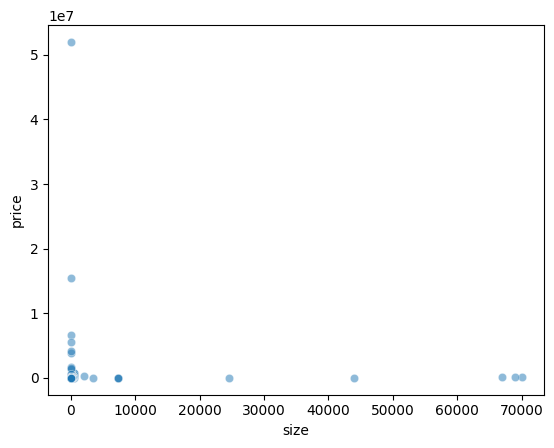

In [151]:
sns.scatterplot(data=df, x='size', y='price', alpha=0.5)
plt.show()

#Vizualizatsiya qilganimda qayerdadir hatolik borligini ko'rdim chunki malumotlar bir joyga yigilib qolgan.

In [152]:
df.describe()

,rooms,size,level,max_levels,price
count,7464.000000,7464.000000,7464.000000,7464.000000,7.464000e+03
mean,2.622454,113.551559,3.693328,6.022776,7.134435e+04
std,1.083297,1501.258234,2.236908,2.604641,6.406092e+05
min,1.000000,1.000000,1.000000,1.000000,2.000000e+00
25%,2.000000,50.000000,2.000000,4.000000,3.500000e+04
50%,3.000000,65.000000,3.000000,5.000000,4.650000e+04
75%,3.000000,85.000000,5.000000,9.000000,6.700000e+04
max,10.000000,70000.000000,19.000000,25.000000,5.200000e+07


#Statistik qiymatlarni tekshirganimizda narx va size ustunlarida ko'rib turganinggizdek noto'gri malumotlar kiritilgan.
# - size uchun: 70,000 (bu aniq anomaliya / xato kiritilgan qiymat). VA min size 1 bo'lishi mumkinmas
# - price uchun: 52,000,000 (bu ham o'ta qimmat yoki xato kiritilgan narx).VA min price 1 bo'lishi mumkinmas

In [153]:
df = df[(df['size'] >= 18) & (df['size'] < 300) & (df['price'] >= 20000) &(df['price'] < 500000)]

In [154]:
df.describe()

,rooms,size,level,max_levels,price
count,7273.000000,7273.000000,7273.000000,7273.000000,7273.000000
mean,2.633026,72.968547,3.698061,6.040423,58758.214079
std,1.037362,32.858089,2.230802,2.602046,41483.104273
min,1.000000,19.000000,1.000000,1.000000,20000.000000
25%,2.000000,50.000000,2.000000,4.000000,35000.000000
50%,3.000000,67.000000,3.000000,5.000000,47000.000000
75%,3.000000,85.000000,5.000000,9.000000,67000.000000
max,8.000000,290.000000,19.000000,25.000000,420000.000000


#Mana endi malumotimiz ancha chiroyli ko'rinishga keldi deb o'ylayman.

#Endi Vizualizatsiya qilib ko'rsak ham bo'ladi.



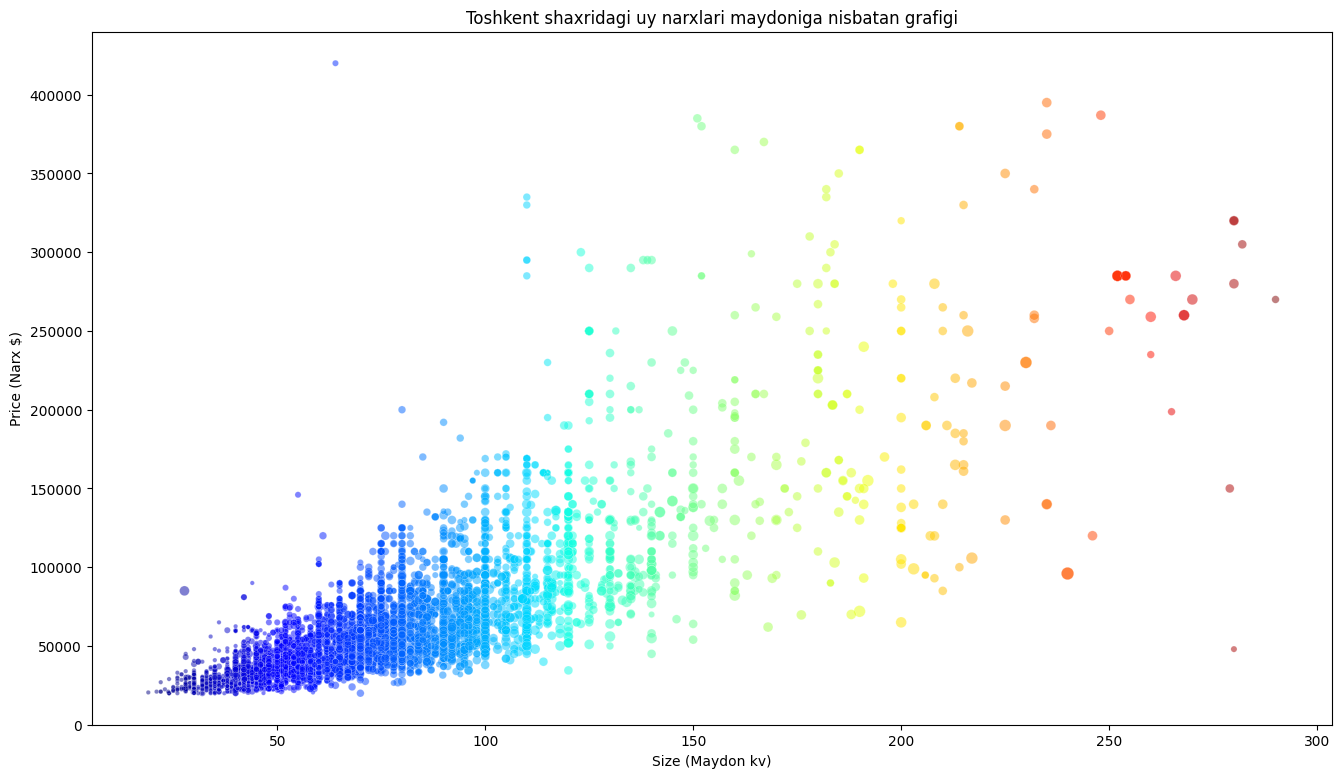

In [162]:
plt.figure(figsize=(16,9))
sns.scatterplot(data=df, x='size', y='price', alpha=0.5, s=df['rooms']*10, c=df["size"], cmap="jet")
plt.title("Toshkent shaxridagi uy narxlari maydoniga nisbatan grafigi")
plt.xlabel("Size (Maydon kv)")
plt.ylabel("Price (Narx $)")
plt.show()

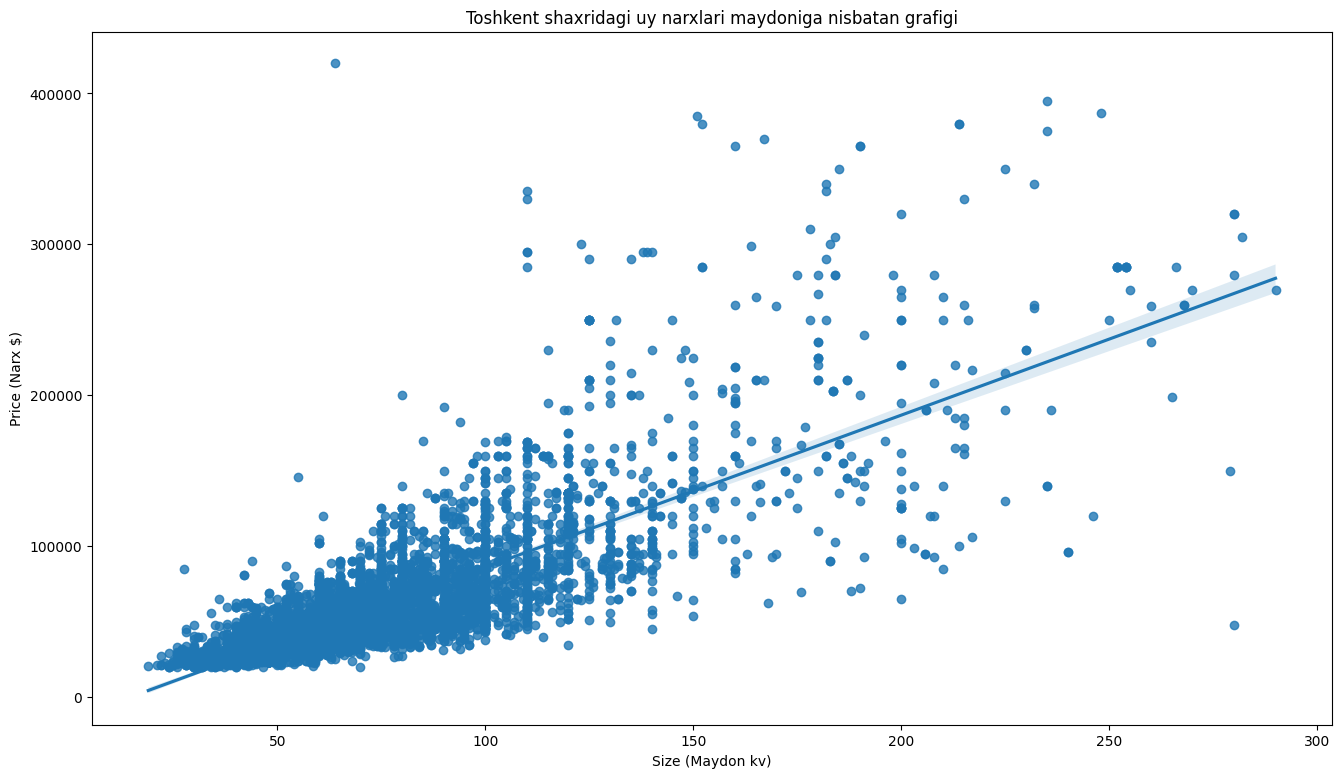

In [167]:
plt.figure(figsize=(16,9))
sns.regplot(data=df, x='size', y='price')
plt.title("Toshkent shaxridagi uy narxlari maydoniga nisbatan grafigi")
plt.xlabel("Size (Maydon kv)")
plt.ylabel("Price (Narx $)")
plt.show()

#Endi Tumanlar bo'yicha grafikka qaraymiz qaysi tumanlarda narx baland va qaysilarida narx pastligini vizual ko'rib tahlil qilamiz.

/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:105: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scout = method(scout_x, scout_y, **kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:553: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  points = ax.scatter(sub_data["x"], sub_data["y"], color=color, **plot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 69.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 55.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 83.6% of the points cannot be placed; you may w

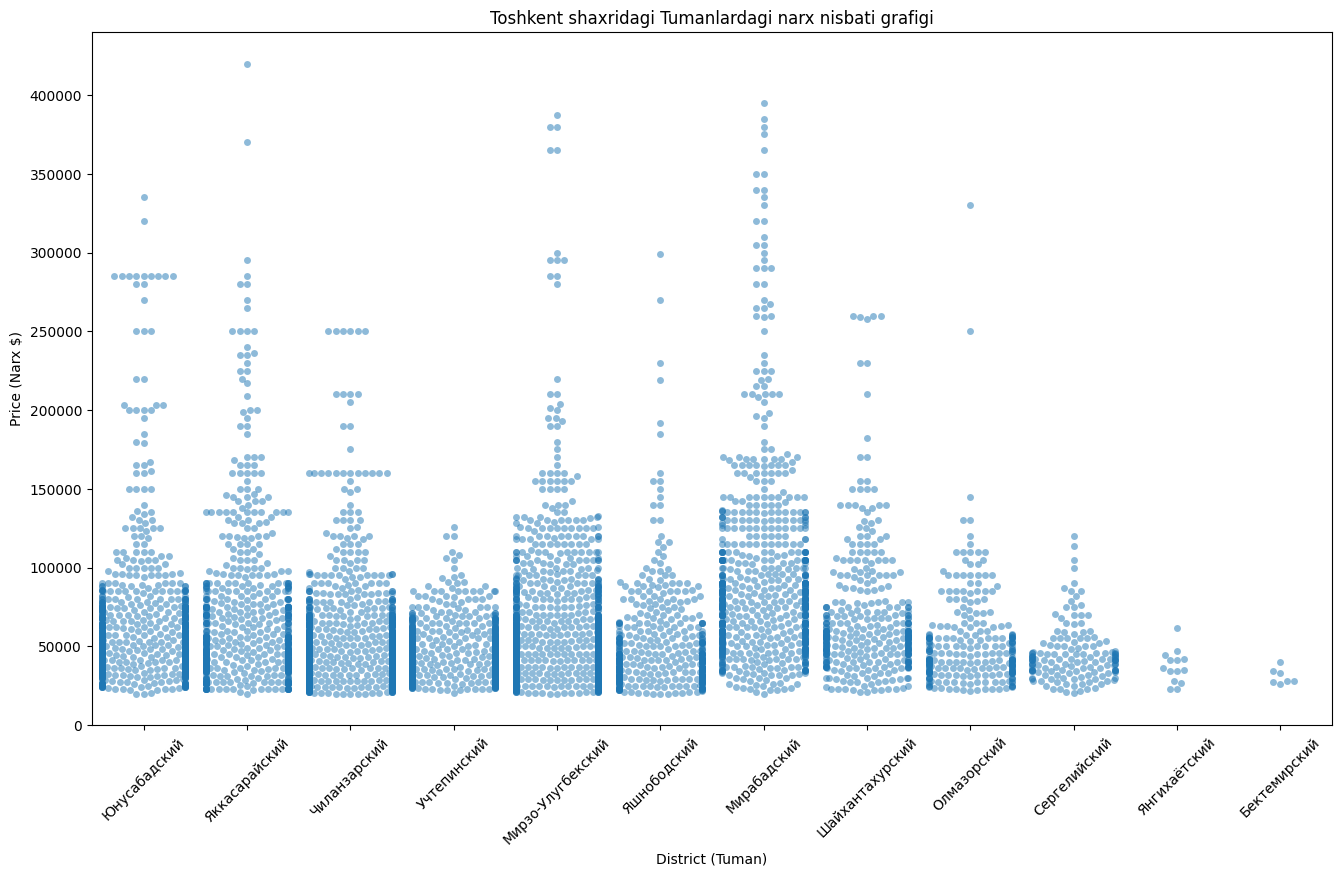

In [164]:
plt.figure(figsize=(16,9))
sns.swarmplot(data=df, x='district', y='price', alpha=0.5, cmap="jet")
plt.title("Toshkent shaxridagi Tumanlardagi narx nisbati grafigi")
plt.xlabel("District (Tuman)")
plt.ylabel("Price (Narx $)")
plt.xticks(rotation=45)
plt.show()

#Yuqoridagi grafikda ko'rinib turibdiki Mirobodda qimmat uylar soni ko'p ekan, Bektemir va Yangixayot da uylar arzon va kam ekan.




#Endi Malumotlarni ML ga tayyorlaymiz.

#Kompyuter string malumotlar bilan ishlamaydi, shuning uchun location va district ustunlarini son qiymatga keltirib olishimiz kerak.

# Analitik yondashuv: Qaysi ML turini tanlaymiz?
#Bizga oldindan  muammo ham yechim ham berilgan?
# Shuning uchun  Supervised turini tanlaymiz.

#Muammo turi (Algoritm) : Regressiya
#Kutilayotgan natija uylarni narxi: Bashorat qilishda regressiyadan foydalanamiz.

#Qaysi usuldan foydalanamiz?  Offline
#Bu loyihamizda OFFLINE usuldan foydalanamiz nimaga chunki malumotlar bizga oldindan berilgan.



#1) MAE - Mean Absolute Error (O'rtacha absolute xatolik)

#2) RMSE - Root Mean Square Error(O'rtacha kvadrat xatolik)

In [181]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

# 1. X (parameters) va y (label bu price ustuni) ni ajratib olamiz
X = df[['rooms', 'size', 'level', 'max_levels', 'district', 'location']]
y = df['price']

# 2. Ma'lumotlarni o'quv va sinov qismlarga bo'lamiz
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Ustunlarni qayta ishlash qoidalari (Preprocessing)
numeric_features = ['rooms', 'size', 'level', 'max_levels']
categorical_features = ['district', 'location']

preprocessor = ColumnTransformer(
    transformers=[
        # Raqamli ustunlarni standartlashtiramiz
        ('num', StandardScaler(), numeric_features),
        # Matnli ustunlarni raqamga o'tkazamiz
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)
    ]
)

# 4. Siz o'rgangan Random Forest modelidan foydalanamiz
model = RandomForestRegressor(n_estimators=150, random_state=42)

# 5. PIPELINE NI TUZAMIZ (Ma'lumotlarni tayyorlash + Model bittada ishlaydi)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model)
])

# 6. Modelni birgina buyruq bilan o'qitamiz
pipeline.fit(X_train, y_train)

# 7. Sinov ma'lumotlari asosida bashorat qilamiz
y_pred = pipeline.predict(X_test)

# 8. Xatolikni (MAE) tekshiramiz
mae = mean_absolute_error(y_test, y_pred)
print(f"Random Forest Pipeline MAE (O'rtacha xatolik): {mae:.2f}")

Random Forest Pipeline MAE (O'rtacha xatolik): 10665.03
